**1. Load the data:** read `exercises.json` into a pandas table, then show its size (rows × columns) and one full record.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("../data/raw/exercises.json", dtype={"id": str})  # keep "0001", not 1
print("shape:", df.shape)
df.iloc[0]

shape: (1324, 15)


id                                                                0001
name                                                        3/4 sit-up
category                                                         waist
body_part                                                        waist
equipment                                                  body weight
instructions         {'en': 'Lie flat on your back with your knees ...
instruction_steps    {'en': ['Lie flat on your back with your knees...
muscle_group                                               hip flexors
secondary_muscles                            [hip flexors, lower back]
target                                                             abs
image                                          images/0001-2gPfomN.jpg
gif_url                                        videos/0001-2gPfomN.gif
media_id                                                       2gPfomN
created_at                            2026-03-18 12:31:32.854798+00:00
attrib

**2. Missing values and duplicate columns:** count empty fields per column, and check whether `category` is just a copy of `body_part`.

In [2]:
missing = df.isna().sum()
empty_lists = df["secondary_muscles"].apply(lambda x: len(x) == 0).sum()
print(missing.to_string())
print("\nempty secondary_muscles lists:", empty_lists)
same = (df["category"] == df["body_part"])
print(f"category == body_part in {same.sum()} / {len(df)} rows")
df.loc[~same, ["name", "category", "body_part"]].head()

id                   0
name                 0
category             0
body_part            0
equipment            0
instructions         0
instruction_steps    0
muscle_group         0
secondary_muscles    0
target               0
image                0
gif_url              0
media_id             0
created_at           0
attribution          0

empty secondary_muscles lists: 0
category == body_part in 1324 / 1324 rows


,name,category,body_part


**3. Value counts:** how many exercises fall into each body part, equipment type and target muscle.

In [3]:
for col in ["body_part", "equipment", "target"]:
    print(f"--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts().to_string(), "\n")

--- body_part (10 unique) ---
body_part
upper arms    292
upper legs    227
back          203
waist         169
chest         163
shoulders     143
lower legs     59
lower arms     37
cardio         29
neck            2 

--- equipment (28 unique) ---
equipment
body weight             325
dumbbell                294
cable                   157
barbell                 154
leverage machine         81
band                     54
smith machine            48
kettlebell               41
weighted                 36
stability ball           28
ez barbell               23
assisted                 15
sled machine             15
medicine ball            13
rope                     10
roller                    8
resistance band           7
bosu ball                 3
olympic barbell           2
wheel roller              2
upper body ergometer      1
skierg machine            1
hammer                    1
stationary bike           1
tire                      1
trap bar                  1
elliptical

**4. Exercises per body part:** a horizontal bar chart, largest at the top, to see how balanced the catalog is.

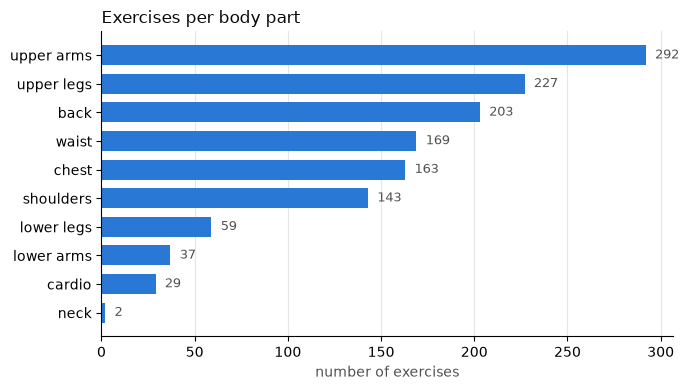

In [4]:
counts = df["body_part"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(counts.index, counts.values, color="#2a78d6", height=0.7)
for y, v in enumerate(counts.values):
    ax.text(v + 5, y, str(v), va="center", fontsize=9, color="#52514e")
ax.set_title("Exercises per body part", loc="left", color="#0b0b0b")
ax.set_xlabel("number of exercises", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**5. Body part × equipment:** a crosstab of the 6 most common equipment types (the rest grouped as `other`), to see which combinations have few exercises.

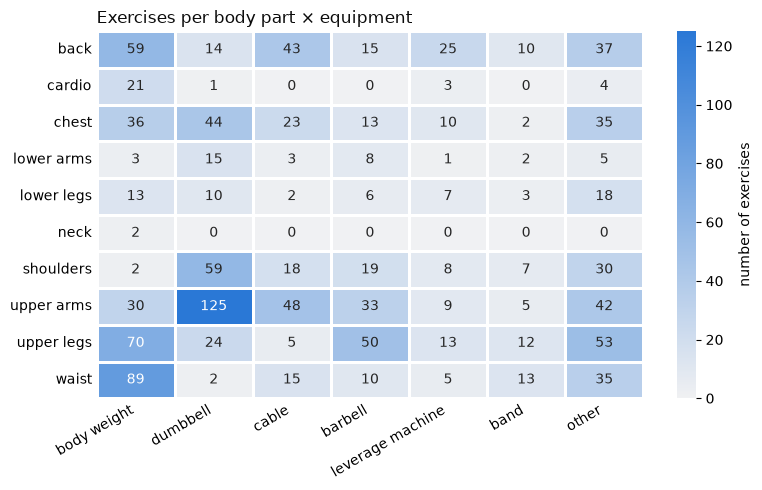

In [5]:
top_eq = df["equipment"].value_counts().index[:6]
eq = df["equipment"].where(df["equipment"].isin(top_eq), "other")
table = pd.crosstab(df["body_part"], eq)
table = table[list(top_eq) + ["other"]]  # most common equipment first

import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(table, annot=True, fmt="d", cmap=sns.light_palette("#2a78d6", as_cmap=True),
            linewidths=2, linecolor="white", cbar_kws={"label": "number of exercises"}, ax=ax)
ax.set_title("Exercises per body part × equipment", loc="left", color="#0b0b0b")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**6. Name quality checks:** duplicate names, suspicious name patterns (`stretch`, `v. 2`, `(male)`), and how long names are in words.

In [6]:
names = df["name"].str.lower()
dups = df[names.duplicated(keep=False)].sort_values("name")
print("duplicate names:", names.duplicated().sum(), "extra copies")
print(dups["name"].head(10).to_string(), "\n")

for pat in ["stretch", "v. 2", "(male)"]:
    hits = df[names.str.contains(pat, regex=False)]["name"]
    print(f"'{pat}': {len(hits)} names, e.g. {hits.head(3).tolist()}")

words = df["name"].str.split().str.len()
print(f"\nname length in words: mean {words.mean():.1f}, max {words.max()}")
print("3 longest names:")
for n in df.loc[words.nlargest(3).index, "name"]:
    print(" -", n)

duplicate names: 6 extra copies
185          barbell seated calf raise
186          barbell seated calf raise
790             ez barbell spider curl
791             ez barbell spider curl
936                  lever chest press
937                  lever chest press
1065       push-up (on stability ball)
1066       push-up (on stability ball)
1124    self assisted inverse leg curl
1125    self assisted inverse leg curl 

'stretch': 57 names, e.g. ['all fours squad stretch', 'assisted lying calves stretch', 'assisted lying glutes stretch']
'v. 2': 37 names, e.g. ['band two legs calf raise - (band under both legs) v. 2', 'barbell rear lunge v. 2', 'barbell revers wrist curl v. 2']
'(male)': 29 names, e.g. ['arms apart circular toe touch (male)', 'arms overhead full sit-up (male)', 'astride jumps (male)']

name length in words: mean 4.2, max 12
3 longest names:
 - band two legs calf raise - (band under both legs) v. 2
 - dumbbell seated one arm bicep curl on exercise ball with leg raised
 

## 7. From exploration to catalog

**`src/build_catalog.py` is the source of truth for `data/processed/catalog.json`.** This notebook only explores; run `python src/build_catalog.py` to rebuild the catalog.

The cleaning rules it applies, based on what we found above:
1. **Drop names containing "stretch":** stretches are warm-up/cool-down moves, not the working sets a workout is built from.
2. **Drop body parts `neck` and `cardio`:** they aren't body parts a user can request (see `docs/spec.md`); neck also has only 2 exercises.
3. **Drop duplicate names, keeping the first:** the 6 repeated names have identical labels, so copies would only teach the model to repeat an exercise.
4. **Drop equipment outside every group** in `src/spec.py` (rope, tire, bikes, …): requests can't ask for it.

It keeps only `id, name, body_part, target, equipment, secondary_muscles`, then adds the `advanced` flag from `data/processed/advanced_ids.json`.